TASK A (Network Construction)

This involves analysing the Wikidata Editor Network which is created from the data. As per mentioned in the instructions in the assignment, assuming that Wikidata User Editors are Nodes of Network and Interactions between them who commented in the same thread on the same page are the Edges. 
The networks are constructed for three datasets:
1. Small - REQUEST_A_QUERY
2. Medium - USERS
3. Large - REQUEST_FOR_DELETION

The same methodology is applied across all datasets to ensure consistency and comparability.

In [2]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from IPython.display import display

Now we'll examine the datasets and understand its structure. All of them are stored in a dictionary so that the same processing pipeline can be applied consistently across all of them.

In [3]:
datasets = {
    "small": "../data/REQUEST_A_QUERY.csv",
    "medium": "../data/USERS.csv",
    "large": "../data/REQUEST_FOR_DELETION.csv"
}

In [4]:
for name, path in datasets.items():
    print(f"{name} dataset")
    df = pd.read_csv(path)
    print("Shape:", df.shape)
    display(df.head())

small dataset
Shape: (5229, 3)


,thread_subject,username,page_name
0,Items with specific string in image filename,Matěj Suchánek,WikidataRequestaqueryArchive201607.json
1,Items with specific string in image filename,Edgars2007,WikidataRequestaqueryArchive201607.json
2,Items with specific string in image filename,Jklamo,WikidataRequestaqueryArchive201607.json
3,Most missing label in a language,Tobias1984,WikidataRequestaqueryArchive201608.json
4,Most missing label in a language,Edgars2007,WikidataRequestaqueryArchive201608.json


medium dataset
Shape: (171692, 3)


,thread_subject,username,page_name
0,No subject,Liuxinyu970226,Usertalk000accountdeleted000.json
1,No subject,M2k~dewiki,Usertalk000selina000.json
2,No subject,Peaceray,Usertalk001Jrm.json
3,No subject,Liuxinyu970226,Usertalk007hemant.json
4,No subject,ToJack,Usertalk011ZezoTito.json


large dataset
Shape: (648644, 3)


,thread_subject,username,page_name
0,[[Q259]],Denny Vrandečić (WMDE),WikidataRequestsfordeletionsArchive20121030.json
1,[[Q292]],Emijrp,WikidataRequestsfordeletionsArchive20121030.json
2,[[Q292]],Vituzzu,WikidataRequestsfordeletionsArchive20121030.json
3,[[Q292]],Denny Vrandečić (WMDE),WikidataRequestsfordeletionsArchive20121030.json
4,[[Q304]],Emijrp,WikidataRequestsfordeletionsArchive20121030.json


Motivation behind modeling the network this way

As per the requirements of the assignment, users are modeled as nodes, while their interactions within the discussion taking place in the page thread are modeled using edges. The lack of explicit information about the reply direction makes it an undirected network.

All the datasets have the same structure with same 3 attributes :-
1) thread_subject - which is the discussion topic'
2) username - user who made the comment
3) page_name - page where the discussion occurred

Each row records a user participating in a specific discussion thread on the given page.
now we will do the data cleaning and construct corresponding connector networks.

In [6]:
def build_graph(df, user_col="username", context_cols=("page_name", "thread_subject"), max_group_size=100):

     # removing incomplete rows
    df = df.dropna().copy()

    # cleaning the textual fields
    df[user_col] = df[user_col].astype(str).str.strip()
    for col in context_cols:
        df[col] = df[col].astype(str).str.strip()

    # initialising graph
    G = nx.Graph()

    # group by page and thread
    for context, group in df.groupby(list(context_cols)):
        users = group[user_col].dropna().unique()

        if len(users) > max_group_size:
            users = users[:max_group_size]

        for u1, u2 in combinations(users, 2):
            G.add_edge(u1, u2)

    return G

The assignement requires assigning ID values for nodes and keeping records of usernames mapping. In this case, numeric ID values are not needed since NetworkX enables assigning labels to nodes. Thus, usernames have been utilized as node IDs during graph formation.

This approach facilitates record keeping while making sure that all nodes are associated with the names of Wikidata editors.

In the development of graph construction algorithm, there is an option for varying the user column and context discussion columns.

The same network construction logic is now applied to the small, medium and large datasets.

In [7]:
graphs = {}
cleaned_dfs = {}

for name, path in datasets.items():
    
    print(f"\n Processing {name} dataset..")
    df = pd.read_csv(path)
    cleaned_dfs[name] = df.dropna().copy()
    
    G = build_graph(df)
    graphs[name] = G

print("\nAll networks constructed successfully.")


 Processing small dataset..

 Processing medium dataset..

 Processing large dataset..

All networks constructed successfully.


Each resulting graph represents a Wikidata Editor Network, where  each unique user becomes a node and shared participation in the same page-thread discussions are represented by edges.
The usernames were directly used to identify the nodes in the graph. This method ensures that there is no need for a secondary mapping from numeric identifiers, and each node corresponds to a unique Wikidata editor.

The resultant graph was modeled as an undirected graph due to the indication that the two participants had taken part in the same thread discussion and not necessarily that one of them sent the reply to the other, since there was no information about who responded to who.

Now we will calculate the number of nodes, number of edges, density, and number of connected components for each network.

In [8]:
summary = []

for name, G in graphs.items():
    nodes = G.number_of_nodes()
    edges = G.number_of_edges()
    density = nx.density(G)
    components = nx.number_connected_components(G)

    summary.append([name, nodes, edges, density, components])

summary_df = pd.DataFrame(
    summary,
    columns = ["Dataset", "Nodes", "Edges", "Density", "Connected Components"]
)

summary_df

,Dataset,Nodes,Edges,Density,Connected Components
0,small,671,1884,0.008381,4
1,medium,8396,24755,0.000702,264
2,large,9887,33497,0.000685,9


The table above provides a basic structural comparison between the 3 networks of varying sizes.


Analyzing the connected components provides some understanding as to whether the graph is under the control of one huge connected component or if it has been divided into several small components.

The connected component shows how fragmented each network is and whether one large connected component dominates the structure.

In [9]:
for name, G in graphs.items():
    
    component_sizes = sorted([len(c) for c in nx.connected_components(G)], reverse=True)

    print(f"\n{name} dataset")
    print("Number of connected components:", len(component_sizes))
    print("Top 10 component sizes:", component_sizes[:10])


small dataset
Number of connected components: 4
Top 10 component sizes: [665, 2, 2, 2]

medium dataset
Number of connected components: 264
Top 10 component sizes: [7774, 8, 6, 6, 6, 6, 6, 6, 5, 5]

large dataset
Number of connected components: 9
Top 10 component sizes: [9870, 3, 2, 2, 2, 2, 2, 2, 2]


Larger connected components mean the communities is sticking toegther. Many small connected groups means the interaction is split into many tiny disconnected groups.

Now we will visualise the networks in which the small and medium networks can be visualised more directly but for large dataset, a sample subgraph of the largest connected component is plotted for readability.

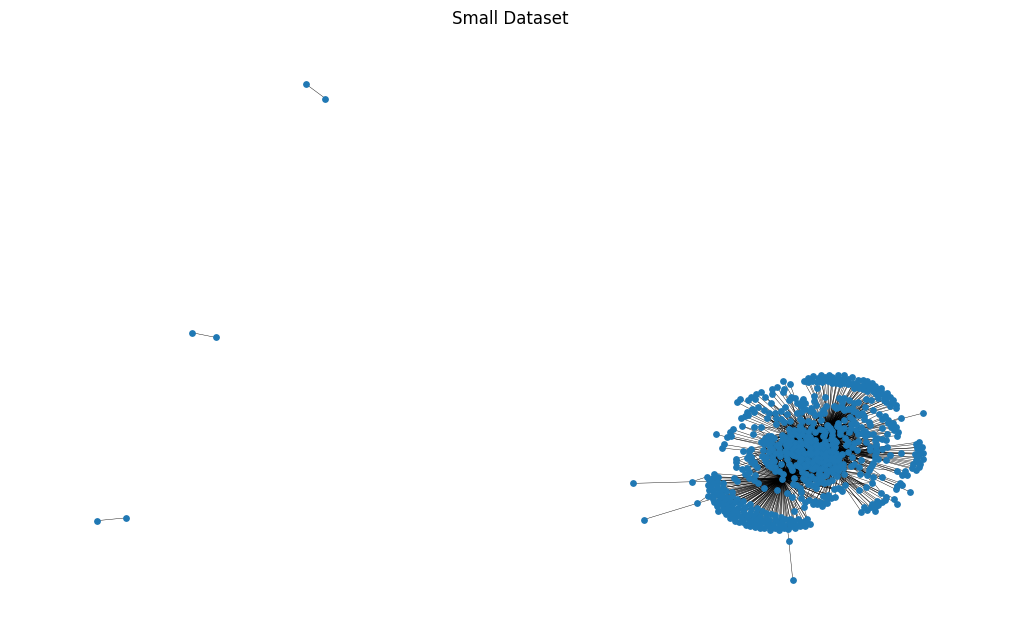

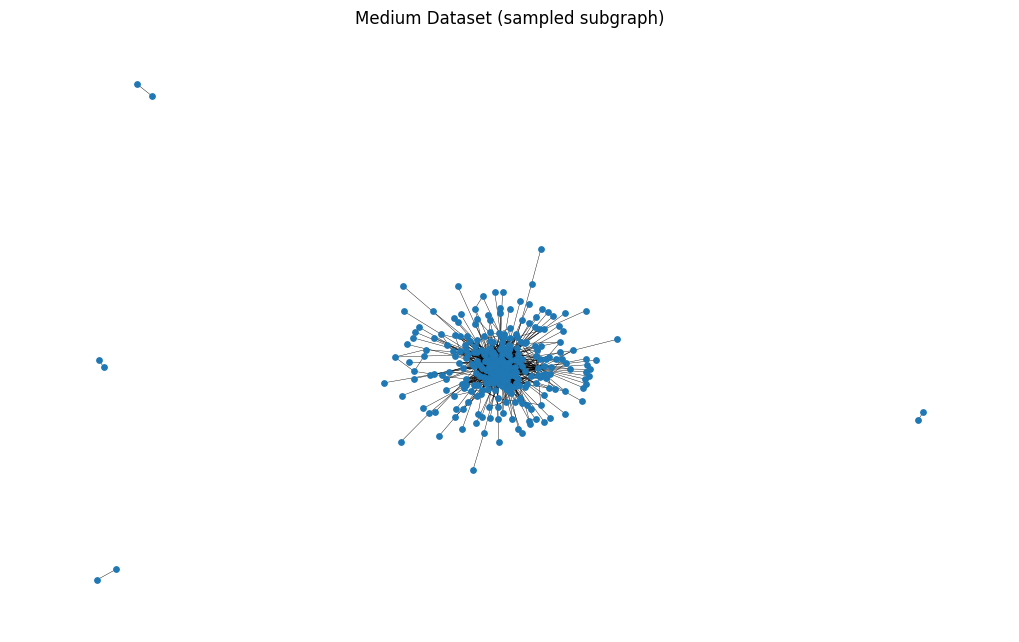

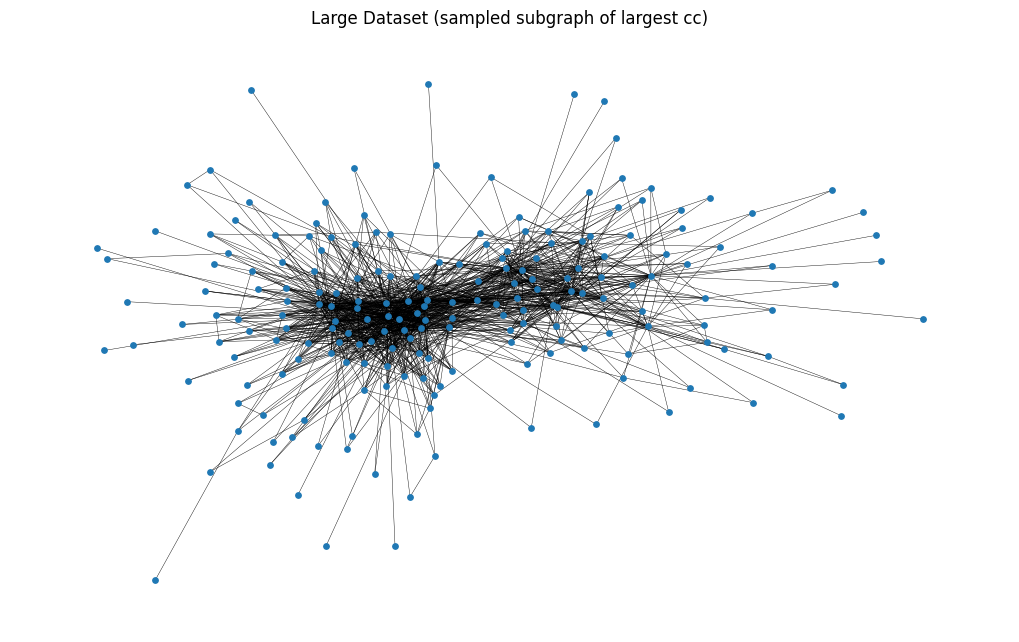

In [15]:
for name, G in graphs.items():

    plt.figure(figsize=(10,6))

    if name == "large":
        largest_cc_nodes = max(nx.connected_components(G), key = len)
        G_lcc = G.subgraph(largest_cc_nodes).copy()

        sample_nodes = list(G_lcc.nodes())[:200]
        G_plot = G_lcc.subgraph(sample_nodes)

        title = "Large Dataset (sampled subgraph of largest cc)"
    
    elif name == "medium":
        # medium can also be hard to read fully so sample if needed
        if G.number_of_nodes() > 300:
            sample_nodes = list(G.nodes())[:300]
            G_plot = G.subgraph(sample_nodes)
            title = "Medium Dataset (sampled subgraph)"
        else:
            G_plot = G
            title = "Medium Dataset"

    else:
        G_plot = G
        title = "Small Dataset"

    nx.draw(G_plot, node_size=15, width=0.3)
    plt.title(title)
    plt.show()

The visualisations show clear differences in scale and connectivity.
1. The small network is easier to inspect directly.
2. The medium network appears a bit visually dense.
3. The large network displayed using subgraph sampling remains interpretable.
These visual differnces already suggest variation in interaction patters across the networks.

This task models Wikidata editor interactions as an undirected graph.
Nodes represent editors identified by 'username'.
Edges represent a social connection between 2 users who commented in the same 'thread_subject' on the same 'page_name'.

The raw tabular data is processed using pandas and the final network is represneted using NetworkX graph

The network construction algorithm groups rows by page and thread, extracts the unique user in each group, and connects all pairs of users within the discussion group.

The model can also be interpreted as a one-mode projection of a network of affiliations. The user takes part in discussion contexts that have been specified based on the page and thread criteria, and the resulting graph of users connected to each other is created through the connection of users who share the same context of discussion.

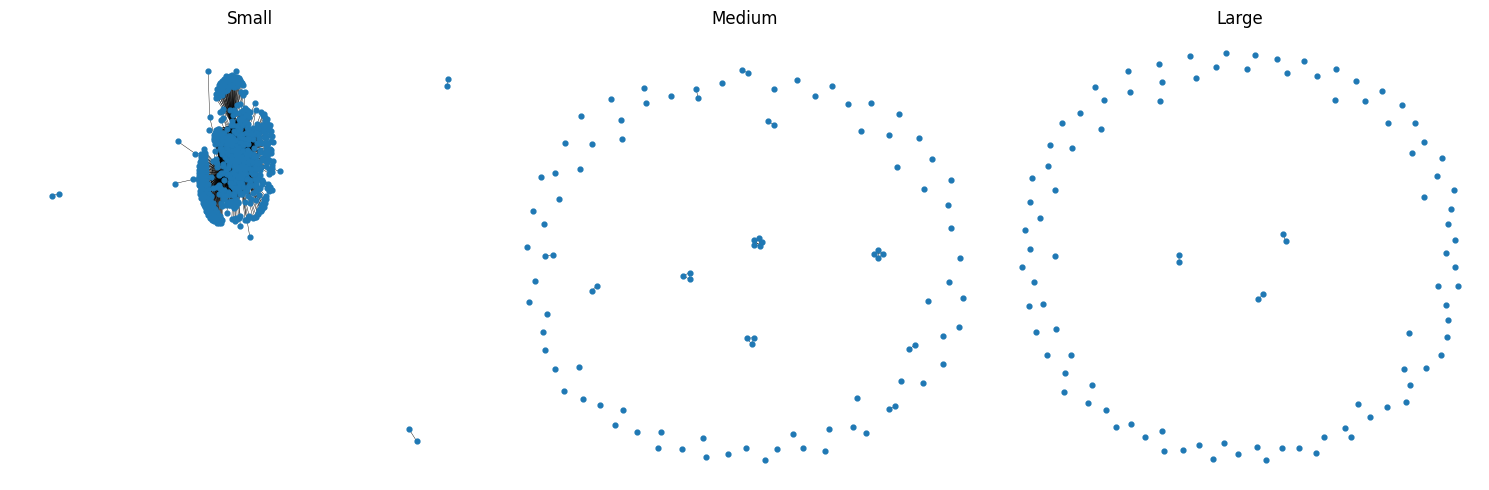

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

plot_graphs = {}

# small = full
plot_graphs["Small"] = graphs["small"]

# medium = sampled largest CC
Gm = graphs["medium"]
lcc_m = max(nx.connected_components(Gm), key=len)
Gm_lcc = Gm.subgraph(lcc_m).copy()
medium_nodes = sorted(Gm_lcc.nodes())[:100]
plot_graphs["Medium"] = Gm_lcc.subgraph(medium_nodes)

# large = sampled largest CC
Gl = graphs["large"]
lcc_l = max(nx.connected_components(Gl), key=len)
Gl_lcc = Gl.subgraph(lcc_l).copy()
large_nodes = sorted(Gl_lcc.nodes())[:100]
plot_graphs["Large"] = Gl_lcc.subgraph(large_nodes)

for ax, (title, Gp) in zip(axes, plot_graphs.items()):
    pos = nx.spring_layout(Gp, seed=42)
    nx.draw(Gp, pos, ax=ax, node_size=12, width=0.3, with_labels=False)
    ax.set_title(title)

plt.tight_layout()
plt.savefig("../report/figures/networks.png", dpi=300)
plt.show()